In [1]:
# Cell 1 — imports, reproducibility, GPU detection
import os
import gc
import json
import math
import random
import warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Avoid allocating all GPU memory immediately.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("Could not enable GPU memory growth:", exc)

print("TensorFlow:", tf.__version__)
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    warnings.warn("No GPU detected. The notebook can run on CPU, but training may be slower.")

TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# Cell 2 — configuration
INPUT_ROOT = Path('/kaggle/input')

# Both files reported in the error are candidates, but neither is trusted until
# its MD5 matches the ORIGINAL official v2 SM background.  Other matching input
# files are discovered automatically.  /kaggle/input is READ-ONLY.
BACKGROUND_CANDIDATES = [
    Path('/kaggle/input/datasets/muhammadalikanjoo/background-training-dataset/background_for_training.h5'),
    Path('/kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/background_for_training_dataset.h5'),
]
BACKGROUND_FILE = None  # Set only after verified, in Cell 3a.
BLACKBOX_FILE = None

SIGNAL_FILES = {
    'A_to_4leptons': None,
    'h0_to_tautau': None,
    'hplus_to_taunu': None,
    'leptoquark_to_btau': None,
}

# Set to False if Kaggle Internet access is disabled; you'll get instructions
# to attach a manually downloaded official v2 file instead of a network error.
AUTO_DOWNLOAD_BACKGROUND = True

BATCH_SIZE = 2048
EPOCHS = 60
LEARNING_RATE = 1e-3
EARLY_STOPPING_PATIENCE = 8
LR_PATIENCE = 3

TRAIN_FRACTION = 0.50
MODEL_VAL_FRACTION = 0.10
CALIBRATION_FRACTION = 0.20
TEST_FRACTION = 0.20
assert np.isclose(TRAIN_FRACTION + MODEL_VAL_FRACTION + CALIBRATION_FRACTION + TEST_FRACTION, 1.0)

PREDICT_BATCH_SIZE = 8192
HDF5_CHUNK_SIZE = 20000
RUN_ISOLATION_FOREST = False
ISOLATION_FOREST_TRAIN_SUBSAMPLE = 100000
OUTPUT_DIR = Path('/kaggle/working/lhc_adc2021_strict_baseline')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET_FPRS = [1e-3, 1e-4, 1e-5]
CHALLENGE_FRACTION = 1e-5
EXPLORATORY_TOP_K = 1000
print('Output directory:', OUTPUT_DIR)


Output directory: /kaggle/working/lhc_adc2021_strict_baseline


In [3]:
# Cell 3 — resolve evaluation input files; gather ALL background candidates.
# Do NOT pick just the first background file or confuse the blackbox with SM training.
def list_h5_files(root=INPUT_ROOT):
    return sorted(p for p in root.rglob('*.h5') if p.is_file()) if root.exists() else []

h5_files = list_h5_files()
print(f'Found {len(h5_files)} HDF5 files under {INPUT_ROOT}:')
for p in h5_files:
    print(' ', p)

def resolve_exact(explicit_path, exact_names, required=True, label='file'):
    if explicit_path is not None:
        p = Path(explicit_path)
        if not p.is_file():
            raise FileNotFoundError(f'{label}: {p}')
        return p
    candidates = [p for p in h5_files if p.name.lower() in {x.lower() for x in exact_names}]
    if len(candidates) == 1:
        return candidates[0]
    if not candidates and not required:
        return None
    if len(candidates) > 1:
        raise RuntimeError(f'Ambiguous {label}; set an explicit path in Cell 2: {candidates}')
    raise FileNotFoundError(f'Missing {label}; attach the corresponding official ADC2021 HDF5 file.')

OFFICIAL_BACKGROUND_NAMES = {
    'background_for_training.h5',
    'background_for_training_dataset.h5',
    'background_for_training_v2.h5',
    'BKG_dataset.h5',
}
background_candidates = []
for p in [*BACKGROUND_CANDIDATES, *h5_files]:
    p = Path(p)
    if not p.is_file() or p.name.lower() not in {x.lower() for x in OFFICIAL_BACKGROUND_NAMES}:
        continue
    if p not in background_candidates:
        background_candidates.append(p)
print('\nBackground candidates to verify (none trusted yet):')
for p in background_candidates: print(' ', p)

BLACKBOX_FILE = resolve_exact(
    BLACKBOX_FILE,
    ['BlackBox_background_mix.h5', 'BlackBox_13TeV_PU20.h5', 'blackbox.h5'],
    required=False, label='blackbox')

signal_patterns = {
    'A_to_4leptons': ['Ato4l_lepFilter_13TeV_filtered.h5'],
    'h0_to_tautau': ['hToTauTau_13TeV_PU20_filtered.h5'],
    'hplus_to_taunu': ['hChToTauNu_13TeV_PU20_filtered.h5'],
    'leptoquark_to_btau': ['leptoquark_LOWMASS_lepFilter_13TeV_filtered.h5'],
}
resolved_signal_files = {}
for label, patterns in signal_patterns.items():
    resolved_signal_files[label] = resolve_exact(SIGNAL_FILES[label], patterns, label=f'signal {label}')

print('\nSelected blackbox:', BLACKBOX_FILE)
for label, path in resolved_signal_files.items():
    print(f'{label}: {path}')


Found 7 HDF5 files under /kaggle/input:
  /kaggle/input/datasets/muhammadalikanjoo/background-training-dataset/background_for_training.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/Ato4l_lepFilter_13TeV_filtered.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/BlackBox_background_mix.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/background_for_training_dataset.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/hChToTauNu_13TeV_PU20_filtered.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/hToTauTau_13TeV_PU20_filtered.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/leptoquark_LOWMASS_lepFilter_13TeV_filtered.h5

Background candidates to verify (none trusted yet):
  /kaggle/input/datasets/muhammadalikanjoo/background-training-dataset/background_for_training.h5
  /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/background_for_training_dataset.

In [4]:
# Cell 3a — verified official v2 training background recovery (Kaggle-safe).
# IMPORTANT: /kaggle/input is read-only; download ONLY under /kaggle/working.
import hashlib
import shutil
import requests

EXPECTED_BACKGROUND_MD5 = '08cb4801229f9d480567f8d3f5cac134'
BACKGROUND_URL = (
    'https://zenodo.org/records/5046428/files/background_for_training.h5?download=1'
)
WORKING_ROOT = Path('/kaggle/working')
LOCAL_BACKGROUND = WORKING_ROOT / 'background_for_training.h5'


def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def verify_official_background(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Background file missing: {path}')
    if 'blackbox' in path.name.lower():
        raise ValueError('Cannot train on the blackbox.')
    if BLACKBOX_FILE is not None and path.resolve() == Path(BLACKBOX_FILE).resolve():
        raise ValueError('Background and blackbox must be different files.')

    print(f'Checking: {path} ({path.stat().st_size / 1e6:.1f} MB)')
    actual_md5 = md5_file(path)
    print(f'  Found MD5:    {actual_md5}')
    print(f'  Official MD5: {EXPECTED_BACKGROUND_MD5}')
    if actual_md5 != EXPECTED_BACKGROUND_MD5:
        raise ValueError('Not identical to official ADC2021 v2 SM background. '
                         'It may be processed, a different version, or incomplete.')

    try:
        with h5py.File(str(path), 'r') as f:
            if 'Particles' not in f:
                raise ValueError(f'Expected Particles dataset; found {list(f.keys())}')
            ds = f['Particles']
            if ds.ndim != 3 or tuple(ds.shape[1:]) != (19, 4):
                raise ValueError(f'Unexpected Particles shape {ds.shape}')
            n = int(ds.shape[0])
            _ = ds[0]
            _ = ds[-1]
    except OSError as exc:
        raise RuntimeError('Checksum matches official file, but h5py cannot read it. '
                           'Investigate h5py/HDF5 compatibility rather than redownloading.') from exc
    print(f'  VERIFIED official v2 training background: {n:,} events')
    return n


def download_official_background(destination):
    destination = Path(destination)
    root = WORKING_ROOT.resolve()
    if not destination.resolve().is_relative_to(root):
        raise ValueError(f'Refusing write outside {root}: {destination}')

    root.mkdir(parents=True, exist_ok=True)
    destination.parent.mkdir(parents=True, exist_ok=True)
    # Fail quickly if writable space is insufficient for a ~646 MB file.
    free_bytes = shutil.disk_usage(root).free
    if free_bytes < 750_000_000:
        raise RuntimeError(f'Insufficient free space in {root}: {free_bytes / 1e6:.1f} MB')

    temp = destination.with_name(destination.name + '.part')
    print(f'\nDownloading the original 646.4 MB background into writable storage: {destination}')
    print('This requires Kaggle Notebook Internet access to be enabled.')
    try:
        with requests.get(BACKGROUND_URL, stream=True, timeout=(25, 180), allow_redirects=True) as response:
            response.raise_for_status()
            with temp.open('wb') as out:
                for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                    if chunk:
                        out.write(chunk)
        print(f'  Received: {temp.stat().st_size / 1e6:.1f} MB; checking MD5...')
        actual = md5_file(temp)
        if actual != EXPECTED_BACKGROUND_MD5:
            raise RuntimeError(f'Download MD5 {actual} != official {EXPECTED_BACKGROUND_MD5}. '
                               'The response may be incomplete or not the expected file.')
        temp.replace(destination)
    except Exception as exc:
        try:
            temp.unlink(missing_ok=True)
        except OSError:
            pass
        raise RuntimeError(
            'Could not download a verified background into /kaggle/working. '
            'If Kaggle Internet is disabled, download background_for_training.h5 '
            'from https://zenodo.org/records/5046428 on your own computer, upload '
            'it as a NEW Kaggle Dataset, attach it to the notebook, then rerun. '
            'Do not rename or use the blackbox or mismatched training file.'
        ) from exc
    return destination


BACKGROUND_FILE = None
BACKGROUND_N = None
BACKGROUND_MD5 = None
tried = set()
for candidate in [LOCAL_BACKGROUND, *background_candidates]:
    p = Path(candidate)
    if p in tried or not p.is_file():
        continue
    tried.add(p)
    try:
        BACKGROUND_N = verify_official_background(p)
        BACKGROUND_FILE = p
        break
    except (OSError, ValueError, FileNotFoundError) as exc:
        print(f'  REJECTED: {exc}')
    # If checksum *matches* but HDF5 is unreadable, allow RuntimeError through.

if BACKGROUND_N is None:
    if not AUTO_DOWNLOAD_BACKGROUND:
        raise RuntimeError(
            'No attached file matches the official v2 checksum. '
            'Download https://zenodo.org/records/5046428/files/background_for_training.h5 '
            'and attach it as a Kaggle Dataset, then rerun.'
        )
    BACKGROUND_FILE = download_official_background(LOCAL_BACKGROUND)
    BACKGROUND_N = verify_official_background(BACKGROUND_FILE)

BACKGROUND_MD5 = EXPECTED_BACKGROUND_MD5
print('\nREADY — Verified training background:', BACKGROUND_FILE)
print('Background events:', BACKGROUND_N)
print('h5py/HDF5:', h5py.__version__, '/', h5py.version.hdf5_version)

if BLACKBOX_FILE is not None:
    if Path(BLACKBOX_FILE).resolve() == Path(BACKGROUND_FILE).resolve():
        raise RuntimeError('Blackbox and training background paths must differ.')
    with h5py.File(str(BLACKBOX_FILE), 'r') as f:
        if 'EvtId' not in f or 'Particles' not in f:
            raise RuntimeError('Expected a separate blackbox file with Particles and EvtId.')
        print('Independent blackbox events:', len(f['Particles']))


Checking: /kaggle/input/datasets/muhammadalikanjoo/background-training-dataset/background_for_training.h5 (144.1 MB)
  Found MD5:    cf412e265c2d9a9951759105ada8197b
  Official MD5: 08cb4801229f9d480567f8d3f5cac134
  REJECTED: Not identical to official ADC2021 v2 SM background. It may be processed, a different version, or incomplete.
Checking: /kaggle/input/datasets/muhammadalikanjoo/lhc-experiment-datasets/background_for_training_dataset.h5 (607.2 MB)
  Found MD5:    fd320b1bd7d2bf661a31c94a5a4288c0
  Official MD5: 08cb4801229f9d480567f8d3f5cac134
  REJECTED: Not identical to official ADC2021 v2 SM background. It may be processed, a different version, or incomplete.

This requires Kaggle Notebook Internet access to be enabled.
  Received: 646.4 MB; checking MD5...
Checking: /kaggle/working/background_for_training.h5 (646.4 MB)
  Found MD5:    08cb4801229f9d480567f8d3f5cac134
  Official MD5: 08cb4801229f9d480567f8d3f5cac134
  VERIFIED official v2 training background: 13,451,915 events


In [5]:
# Cell 4 — common preprocessing
N_OBJECTS = 19
N_KINEMATIC_FEATURES = 3
N_FEATURES = N_OBJECTS * N_KINEMATIC_FEATURES


def to_flat_kinematic_features(x, apply_log_pt=True):
    """Convert one batch to float32 (N, 57), retaining pT/eta/phi only."""
    x = np.asarray(x, dtype=np.float32)

    if x.ndim == 3:
        if x.shape[1:] == (19, 4):
            x = x[:, :, :3]  # Drop object-type channel.
        elif x.shape[1:] == (19, 3):
            pass
        else:
            raise ValueError(f"Unexpected 3D event shape: {x.shape}; expected (N,19,4) or (N,19,3).")
        x3 = x
    elif x.ndim == 2:
        if x.shape[1] == 76:
            x3 = x.reshape(-1, 19, 4)[:, :, :3]
        elif x.shape[1] == 57:
            x3 = x.reshape(-1, 19, 3)
        else:
            raise ValueError(f"Unexpected 2D feature shape: {x.shape}; expected 57 or 76 columns.")
    else:
        raise ValueError(f"Unexpected input rank {x.ndim}, shape={x.shape}.")

    x3 = np.array(x3, dtype=np.float32, copy=True)
    if apply_log_pt:
        # Correctly transform each object's pT, not only the first flattened column.
        x3[:, :, 0] = np.log1p(np.maximum(x3[:, :, 0], 0.0))

    flat = x3.reshape(-1, N_FEATURES)
    if not np.isfinite(flat).all():
        raise ValueError("Input contains NaN or infinite values after preprocessing.")
    return flat


def standardize_in_place(x, mean, std):
    x -= mean.astype(np.float32)
    x /= std.astype(np.float32)
    return x


def fit_training_scaler(x_train):
    mean = x_train.mean(axis=0, dtype=np.float64).astype(np.float32)
    std = x_train.std(axis=0, dtype=np.float64).astype(np.float32)
    std[std < 1e-6] = 1.0
    return mean, std

In [6]:
# Cell 5 — create four independent background splits from official Particles.
def load_background_splits(path):
    with h5py.File(path,'r') as f:
        print('Training background keys:',list(f.keys()))
        particles=f['Particles'][:].astype(np.float32,copy=False)
    n=len(particles)
    idx=np.arange(n)
    train_idx, remaining_idx=train_test_split(idx,train_size=TRAIN_FRACTION,random_state=SEED,shuffle=True)
    # The remainder includes model validation, calibration, and held-out test.
    model_val_idx, remaining_idx=train_test_split(
        remaining_idx,train_size=MODEL_VAL_FRACTION/(1.0-TRAIN_FRACTION),
        random_state=SEED+1,shuffle=True)
    calib_idx,test_idx=train_test_split(
        remaining_idx,train_size=CALIBRATION_FRACTION/(CALIBRATION_FRACTION+TEST_FRACTION),
        random_state=SEED+2,shuffle=True)
    # np.unique is safer on Kaggle RAM than constructing 6 large Python sets.
    assert sum(map(len,[train_idx,model_val_idx,calib_idx,test_idx]))==n
    assert len(np.unique(np.concatenate([train_idx,model_val_idx,calib_idx,test_idx])))==n
    x_train=to_flat_kinematic_features(particles[np.sort(train_idx)])
    x_val=to_flat_kinematic_features(particles[np.sort(model_val_idx)])
    x_cal=to_flat_kinematic_features(particles[np.sort(calib_idx)])
    x_test=to_flat_kinematic_features(particles[np.sort(test_idx)])
    del particles, idx,train_idx,model_val_idx,calib_idx,test_idx
    gc.collect()
    print('Train, model-val, calibration, test shapes:',x_train.shape,x_val.shape,x_cal.shape,x_test.shape)
    return x_train,x_val,x_cal,x_test

X_train_raw,X_val_raw,X_cal_raw,X_test_raw=load_background_splits(BACKGROUND_FILE)
scaler_mean,scaler_std=fit_training_scaler(X_train_raw)
X_train=standardize_in_place(X_train_raw,scaler_mean,scaler_std)
X_val=standardize_in_place(X_val_raw,scaler_mean,scaler_std)
X_cal=standardize_in_place(X_cal_raw,scaler_mean,scaler_std)
X_test=standardize_in_place(X_test_raw,scaler_mean,scaler_std)
del X_train_raw,X_val_raw,X_cal_raw,X_test_raw
gc.collect()
print('Feature count:',X_train.shape[1])


Training background keys: ['Particles', 'Particles_Classes', 'Particles_Names']
Train, model-val, calibration, test shapes: (6725957, 57) (1345191, 57) (2690383, 57) (2690384, 57)
Feature count: 57


In [7]:
# Cell 6 — dimensionality, finiteness, provenance and calibration separation.
for x in (X_train,X_val,X_cal,X_test):
    assert x.ndim==2 and x.shape[1]==57
    assert np.isfinite(x).all()
assert len(X_train)+len(X_val)+len(X_cal)+len(X_test)==BACKGROUND_N
assert np.all(np.abs(X_train.mean(axis=0))<2e-2)
print('Train, val, cal, test lengths:',*[len(x) for x in (X_train,X_val,X_cal,X_test)])


Train, val, cal, test lengths: 6725957 1345191 2690383 2690384


In [8]:
# Cell 7 — define the autoencoder and encoder explicitly

def build_autoencoder(input_dim=57, learning_rate=1e-3):
    inputs = keras.Input(shape=(input_dim,), name="event_features")
    x = layers.Dense(256, activation="relu", name="encoder_dense_256")(inputs)
    x = layers.Dropout(0.30, name="encoder_dropout")(x)
    x = layers.Dense(128, activation="relu", name="encoder_dense_128")(x)
    bottleneck = layers.Dense(64, activation="relu", name="bottleneck_64")(x)
    x = layers.Dense(128, activation="relu", name="decoder_dense_128")(bottleneck)
    x = layers.Dense(256, activation="relu", name="decoder_dense_256")(x)
    outputs = layers.Dense(input_dim, activation=None, name="reconstruction")(x)

    autoencoder = keras.Model(inputs, outputs, name="lhc_dense_autoencoder")
    encoder = keras.Model(inputs, bottleneck, name="lhc_encoder")
    autoencoder.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
    )
    return autoencoder, encoder


autoencoder, encoder = build_autoencoder(N_FEATURES, LEARNING_RATE)
autoencoder.summary()
print("Encoder output shape:", encoder.output_shape)

Model: "lhc_dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ event_features (InputLayer)     │ (None, 57)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_256 (Dense)       │ (None, 256)            │        14,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout (Dropout)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_128 (Dense)       │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck_64 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_128 (Dense)       │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_256 (Dense)       │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 57)             │        14,649 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,993 (437.47 KB)

 Trainable params: 111,993 (437.47 KB)

 Non-trainable params: 0 (0.00 B)

Encoder output shape: (None, 64)


In [9]:
# Cell 8 — train on X_train only; validation is used only for model selection

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / "best_autoencoder.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
]

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)

# Restore the best saved validation checkpoint as an extra safeguard.
autoencoder = keras.models.load_model(OUTPUT_DIR / "best_autoencoder.keras")
encoder = keras.Model(
    autoencoder.input,
    autoencoder.get_layer("bottleneck_64").output,
    name="lhc_encoder",
)

Epoch 1/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - loss: 0.1849 - val_loss: 0.0622 - learning_rate: 0.0010
Epoch 2/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - loss: 0.1040 - val_loss: 0.0541 - learning_rate: 0.0010
Epoch 3/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0879 - val_loss: 0.0412 - learning_rate: 0.0010
Epoch 4/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0810 - val_loss: 0.0500 - learning_rate: 0.0010
Epoch 5/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0743 - val_loss: 0.0403 - learning_rate: 0.0010
Epoch 6/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0670 - val_loss: 0.0360 - learning_rate: 0.0010
Epoch 7/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0657 - val_loss: 0.0379 - learning_rate: 0.0010
Epoch 8/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0614 - val_loss: 0.0374 - learning_rate: 0.0010
Epoch 9/60
3285/3285 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: 0.0621 - val_loss: 0.0352 - learn

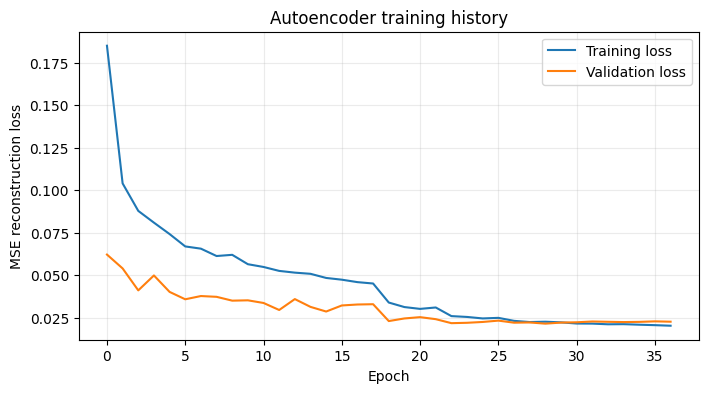

Best validation epoch: 29
Best validation MSE: 0.021652234718203545


In [10]:
# Cell 9 — plot the training history

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE reconstruction loss")
plt.title("Autoencoder training history")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
print("Best validation epoch:", best_epoch)
print("Best validation MSE:", float(np.min(history.history["val_loss"])))

Calibration background score summary: count    2.690383e+06
mean     2.205093e-02
std      1.728327e+00
min      1.257767e-04
25%      5.713092e-03
50%      9.750326e-03
75%      1.580052e-02
max      2.646438e+03
dtype: float64
Test background score summary: count    2.690384e+06
mean     2.297408e-02
std      1.110682e+00
min      1.085875e-04
25%      5.712637e-03
50%      9.750079e-03
75%      1.579731e-02
max      1.184314e+03
dtype: float64


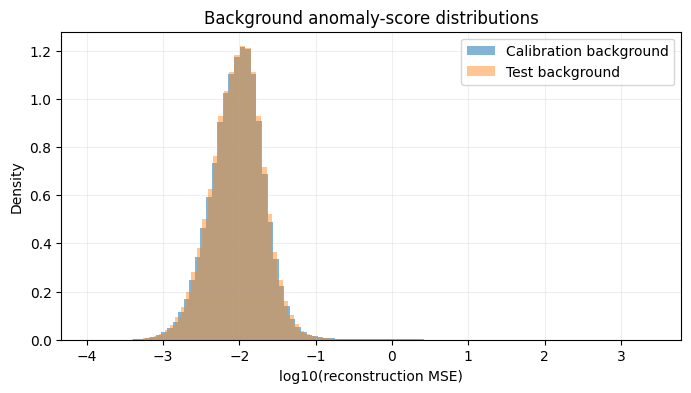

In [11]:
# Cell 10 — batched scoring utilities

def score_array(model, x, batch_size=PREDICT_BATCH_SIZE):
    """Return one MSE reconstruction score per row."""
    scores = np.empty(len(x), dtype=np.float32)
    for start in range(0, len(x), batch_size):
        end = min(start + batch_size, len(x))
        batch = x[start:end]
        reconstructed = model.predict(batch, batch_size=batch_size, verbose=0)
        scores[start:end] = np.mean(np.square(batch - reconstructed), axis=1)
    return scores


val_background_scores = score_array(autoencoder, X_val)
cal_background_scores = score_array(autoencoder, X_cal)
test_background_scores = score_array(autoencoder, X_test)

print("Calibration background score summary:", pd.Series(cal_background_scores).describe())
print("Test background score summary:", pd.Series(test_background_scores).describe())

plt.figure(figsize=(8, 4))
plt.hist(np.log10(np.maximum(cal_background_scores, 1e-12)), bins=100, density=True, alpha=0.55, label="Calibration background")
plt.hist(np.log10(np.maximum(test_background_scores, 1e-12)), bins=100, density=True, alpha=0.45, label="Test background")
plt.xlabel("log10(reconstruction MSE)")
plt.ylabel("Density")
plt.title("Background anomaly-score distributions")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [12]:
# Cell 11 — conservative threshold calibration from disjoint background CALIBRATION split.
from scipy.stats import beta

def confidence_interval_binomial(k,n,alpha=0.05):
    # Exact Clopper-Pearson two-sided 95% interval.
    lower=0.0 if k==0 else float(beta.ppf(alpha/2,k,n-k+1))
    upper=1.0 if k==n else float(beta.ppf(1-alpha/2,k+1,n-k))
    return lower,upper

def threshold_for_target_fpr(cal_scores,target_fpr):
    scores=np.asarray(cal_scores,dtype=np.float64)
    n=len(scores)
    # Conservative count: at most floor(target_fpr*n) calibration events accepted.
    allowed=int(np.floor(target_fpr*n))
    if allowed==0:
        threshold=np.nextafter(float(np.max(scores)),np.inf)
    else:
        # Push threshold just above the (allowed+1)-th largest score.
        kth=np.partition(scores,n-allowed-1)[n-allowed-1]
        threshold=np.nextafter(float(kth),np.inf)
    realized=int(np.sum(scores>=threshold))
    assert realized<=allowed
    return threshold,realized,allowed

threshold_rows=[]
for target in TARGET_FPRS:
    threshold,k_cal,k_allowed=threshold_for_target_fpr(cal_background_scores,target)
    k_test=int(np.sum(test_background_scores>=threshold))
    lo,hi=confidence_interval_binomial(k_test,len(test_background_scores))
    threshold_rows.append({
        'target_fpr':target,'threshold_from_calibration':threshold,
        'calibration_tail_events':k_cal,'calibration_background_n':len(cal_background_scores),
        'calibration_fpr':k_cal/len(cal_background_scores),
        'allowed_calibration_events':k_allowed,
        'test_false_positives':k_test,'test_background_n':len(test_background_scores),
        'test_background_fpr':k_test/len(test_background_scores),
        'test_fpr_ci95_lower':lo,'test_fpr_ci95_upper':hi,
    })
threshold_table=pd.DataFrame(threshold_rows)
display(threshold_table)
threshold_table.to_csv(OUTPUT_DIR/'calibration_thresholds.csv',index=False)
print('Interpret FPR=1e-5 as uncertain unless you have a much larger independent sample.')


,target_fpr,threshold_from_calibration,calibration_tail_events,calibration_background_n,calibration_fpr,allowed_calibration_events,test_false_positives,test_background_n,test_background_fpr,test_fpr_ci95_lower,test_fpr_ci95_upper
0,0.00100,1.060852,2690,2690383,0.00100,2690,2810,2690384,0.001044,0.001006,0.001084
1,0.00010,14.621846,269,2690383,0.00010,269,289,2690384,0.000107,0.000095,0.000121
2,0.00001,96.900719,26,2690383,0.00001,26,45,2690384,0.000017,0.000012,0.000022


Interpret FPR=1e-5 as uncertain unless you have a much larger independent sample.


In [13]:
# Cell 12 — generic HDF5 event reader and scorer for signal/blackbox datasets

def _choose_event_key(h5_file):
    for key in ["Particles", "Data", "X"]:
        if key in h5_file:
            return key
    raise KeyError(f"No Particles/Data/X dataset found. HDF5 keys: {list(h5_file.keys())}")


def score_hdf5_events(model, path, mean, std, chunk_size=HDF5_CHUNK_SIZE, return_event_ids=False):
    """Stream a signal/blackbox HDF5 dataset and return anomaly scores."""
    all_scores = []
    all_event_ids = []
    with h5py.File(path, "r") as f:
        event_key = _choose_event_key(f)
        ds = f[event_key]
        n_events = int(ds.shape[0])
        ids_ds = f["EvtId"] if "EvtId" in f else None

        for start in range(0, n_events, chunk_size):
            end = min(start + chunk_size, n_events)
            raw = ds[start:end]
            features = to_flat_kinematic_features(raw)
            standardize_in_place(features, mean, std)
            scores = score_array(model, features)
            all_scores.append(scores)

            if return_event_ids:
                if ids_ds is None:
                    raise KeyError("Blackbox file must contain EvtId to export event rankings.")
                all_event_ids.append(np.asarray(ids_ds[start:end]))

            del raw, features, scores

    scores_out = np.concatenate(all_scores).astype(np.float32, copy=False)
    if return_event_ids:
        ids_out = np.concatenate(all_event_ids)
        return scores_out, ids_out
    return scores_out


def evaluate_signal_file(label, path):
    if path is None:
        print(f"Skipping {label}: no HDF5 file found/configured.")
        return None
    signal_scores = score_hdf5_events(autoencoder, path, scaler_mean, scaler_std)

    y_true = np.concatenate([
        np.zeros(len(test_background_scores), dtype=np.int8),
        np.ones(len(signal_scores), dtype=np.int8),
    ])
    y_score = np.concatenate([test_background_scores, signal_scores])

    auc = float(roc_auc_score(y_true, y_score))
    ap = float(average_precision_score(y_true, y_score))
    prevalence = float(len(signal_scores) / (len(test_background_scores) + len(signal_scores)))
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)

    # Highest TPR whose empirical test FPR does not exceed target.
    roc_tpr_at_fpr = {}
    for target in TARGET_FPRS:
        valid = np.flatnonzero(fpr <= target)
        roc_tpr_at_fpr[target] = float(tpr[valid[-1]]) if len(valid) else 0.0

    # Use thresholds calibrated with validation background only.
    calibrated = {}
    for _, row in threshold_table.iterrows():
        target = float(row["target_fpr"])
        threshold = float(row["threshold_from_calibration"])
        calibrated[target] = {
            "test_fpr": float(np.mean(test_background_scores >= threshold)),
            "signal_tpr": float(np.mean(signal_scores >= threshold)),
            "threshold": threshold,
        }

    result = {
        "signal": label,
        "n_signal": int(len(signal_scores)),
        "roc_auc": auc,
        "average_precision": ap,
        "positive_prevalence_in_pair": prevalence,
    }
    for target in TARGET_FPRS:
        tag = f"{target:.0e}"
        result[f"test_roc_tpr_at_fpr_{tag}"] = roc_tpr_at_fpr[target]
        result[f"calibrated_test_fpr_{tag}"] = calibrated[target]["test_fpr"]
        result[f"calibrated_signal_tpr_{tag}"] = calibrated[target]["signal_tpr"]

    return result, signal_scores, (fpr, tpr)


signal_results = []
signal_score_map = {}
roc_curve_map = {}
for label, path in resolved_signal_files.items():
    evaluated = evaluate_signal_file(label, path)
    if evaluated is not None:
        result, scores, roc_data = evaluated
        signal_results.append(result)
        signal_score_map[label] = scores
        roc_curve_map[label] = roc_data

if not signal_results:
    raise RuntimeError("No signal HDF5 files were found. Add the four signal files to Kaggle Inputs or set SIGNAL_FILES manually.")

metrics_df = pd.DataFrame(signal_results)
display(metrics_df)
metrics_df.to_csv(OUTPUT_DIR / "signal_metrics.csv", index=False)

print("Macro-average ROC-AUC:", metrics_df["roc_auc"].mean())
print("Macro-average AP (mean of per-signal APs; not a blackbox AP):", metrics_df["average_precision"].mean())

,signal,n_signal,roc_auc,average_precision,positive_prevalence_in_pair,test_roc_tpr_at_fpr_1e-03,calibrated_test_fpr_1e-03,calibrated_signal_tpr_1e-03,test_roc_tpr_at_fpr_1e-04,calibrated_test_fpr_1e-04,calibrated_signal_tpr_1e-04,test_roc_tpr_at_fpr_1e-05,calibrated_test_fpr_1e-05,calibrated_signal_tpr_1e-05
0,A_to_4leptons,55969,0.848979,0.358698,0.020379,0.142097,0.001044,0.146974,0.076810,0.000107,0.079419,0.022566,0.000017,0.032750
1,h0_to_tautau,691283,0.595309,0.337113,0.204421,0.024582,0.001044,0.025247,0.003862,0.000107,0.004071,0.000735,0.000017,0.000974
2,hplus_to_taunu,760272,0.628943,0.435486,0.220327,0.023108,0.001044,0.024157,0.002339,0.000107,0.002498,0.000463,0.000017,0.000629
3,leptoquark_to_btau,340544,0.688069,0.287264,0.112356,0.017149,0.001044,0.018001,0.001838,0.000107,0.001956,0.000391,0.000017,0.000593


Macro-average ROC-AUC: 0.690325106792437
Macro-average AP (mean of per-signal APs; not a blackbox AP): 0.35463998770700483


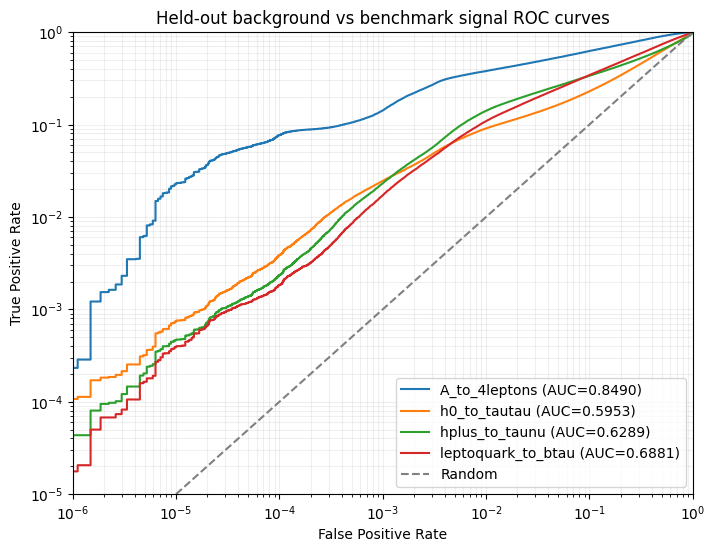

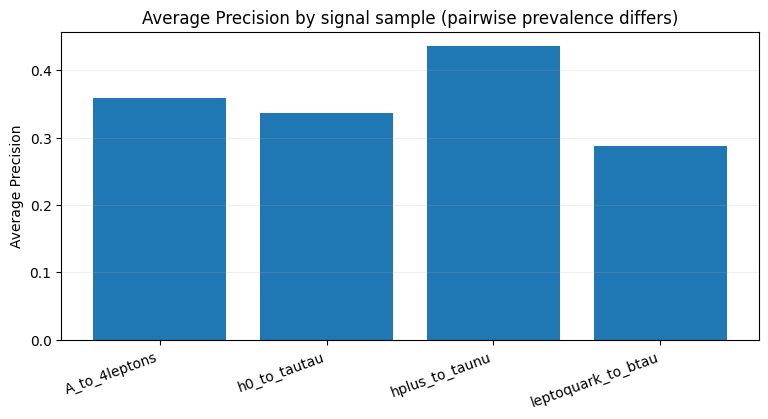

In [14]:
# Cell 13 — plot ROC curves for each signal and report macro means

plt.figure(figsize=(8, 6))
for label, (fpr, tpr) in roc_curve_map.items():
    auc_value = metrics_df.loc[metrics_df["signal"] == label, "roc_auc"].iloc[0]
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc_value:.4f})")
plt.plot([1e-6, 1], [1e-6, 1], "--", color="gray", label="Random")
plt.xscale("log")
plt.yscale("log")
plt.xlim(1e-6, 1)
plt.ylim(1e-5, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Held-out background vs benchmark signal ROC curves")
plt.grid(True, which="both", alpha=0.2)
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(metrics_df["signal"], metrics_df["average_precision"])
plt.ylabel("Average Precision")
plt.title("Average Precision by signal sample (pairwise prevalence differs)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.show()

In [15]:
RUN_ISOLATION_FOREST=True

In [16]:
# Cell 14 — optional Isolation Forest experiment (disabled by default)

if RUN_ISOLATION_FOREST:
    from sklearn.ensemble import IsolationForest

    rng = np.random.default_rng(SEED)
    n_sub = min(ISOLATION_FOREST_TRAIN_SUBSAMPLE, len(X_train))
    train_indices = rng.choice(len(X_train), size=n_sub, replace=False)

    train_embeddings = encoder.predict(
        X_train[train_indices], batch_size=PREDICT_BATCH_SIZE, verbose=1
    )
    iso_forest = IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=SEED,
        n_jobs=-1,
    )
    iso_forest.fit(train_embeddings)

    test_embeddings = encoder.predict(X_test, batch_size=PREDICT_BATCH_SIZE, verbose=1)
    iso_test_scores = -iso_forest.decision_function(test_embeddings)

    isolation_rows = []
    for label, path in resolved_signal_files.items():
        if path is None:
            continue
        # Score signals in chunks; use the same preprocessing/scaler and bottleneck.
        signal_embeddings = []
        with h5py.File(path, "r") as f:
            key = _choose_event_key(f)
            ds = f[key]
            for start in range(0, len(ds), HDF5_CHUNK_SIZE):
                raw = ds[start:start + HDF5_CHUNK_SIZE]
                xx = to_flat_kinematic_features(raw)
                standardize_in_place(xx, scaler_mean, scaler_std)
                signal_embeddings.append(encoder.predict(xx, batch_size=PREDICT_BATCH_SIZE, verbose=0))
        signal_embeddings = np.concatenate(signal_embeddings)
        iso_signal_scores = -iso_forest.decision_function(signal_embeddings)
        yy = np.r_[np.zeros(len(iso_test_scores)), np.ones(len(iso_signal_scores))]
        ss = np.r_[iso_test_scores, iso_signal_scores]
        isolation_rows.append({
            "signal": label,
            "roc_auc": roc_auc_score(yy, ss),
            "average_precision": average_precision_score(yy, ss),
            "n_signal": len(iso_signal_scores),
        })

    isolation_df = pd.DataFrame(isolation_rows)
    display(isolation_df)
    isolation_df.to_csv(OUTPUT_DIR / "isolation_forest_metrics.csv", index=False)
else:
    print("Isolation Forest skipped. Set RUN_ISOLATION_FOREST=True in Cell 2 to run the optional comparison.")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
329/329 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


,signal,roc_auc,average_precision,n_signal
0,A_to_4leptons,0.882010,0.226516,55969
1,h0_to_tautau,0.656670,0.398437,691283
2,hplus_to_taunu,0.829646,0.618164,760272
3,leptoquark_to_btau,0.779836,0.375140,340544


In [17]:
# Cell 15 — rank the blackbox sample (no labels used)

if BLACKBOX_FILE is None:
    print("No blackbox file found/configured. Skipping blackbox ranking.")
else:
    blackbox_scores, blackbox_event_ids = score_hdf5_events(
        autoencoder,
        BLACKBOX_FILE,
        scaler_mean,
        scaler_std,
        chunk_size=HDF5_CHUNK_SIZE,
        return_event_ids=True,
    )

    if len(blackbox_scores) != len(blackbox_event_ids):
        raise AssertionError("Blackbox event IDs and scores have different lengths.")
    if len(np.unique(blackbox_event_ids)) != len(blackbox_event_ids):
        warnings.warn("Blackbox EvtId values are not unique; check the source dataset.")

    # Full rank order is sorted in descending anomaly score.
    order = np.argsort(blackbox_scores)[::-1]

    top_k = min(EXPLORATORY_TOP_K, len(order))
    top1000_idx = order[:top_k]
    top1000_df = pd.DataFrame({
        "EvtId": blackbox_event_ids[top1000_idx],
        "score": blackbox_scores[top1000_idx],
    })
    top1000_df.to_csv(OUTPUT_DIR / "blackbox_top_1000.csv", index=False)

    challenge_k = max(1, int(round(CHALLENGE_FRACTION * len(order))))
    challenge_idx = order[:challenge_k]
    challenge_df = pd.DataFrame({
        "EvtId": blackbox_event_ids[challenge_idx],
        "score": blackbox_scores[challenge_idx],
    })
    challenge_df.to_csv(OUTPUT_DIR / "blackbox_top_1e-5_fraction.csv", index=False)

    print("Blackbox event count:", len(order))
    print("Exploratory Top-K count:", len(top1000_df))
    print("Challenge fraction:", CHALLENGE_FRACTION)
    print("Challenge selection count:", len(challenge_df))
    print("Top 10 candidates:")
    display(top1000_df.head(10))

Blackbox event count: 1001000
Exploratory Top-K count: 1000
Challenge fraction: 1e-05
Challenge selection count: 10
Top 10 candidates:


,EvtId,score
0,681439,198.513733
1,259617,189.578583
2,548420,180.647736
3,922704,162.384521
4,668466,162.147888
5,379708,158.075027
6,654471,157.444702
7,394560,138.580338
8,6768,134.137268
9,583315,133.618134


In [18]:
# Cell 16 — save model, preprocessing parameters, results and run metadata

# Save the model after restoring the best validation checkpoint.
autoencoder.save(OUTPUT_DIR / "lhc_dense_autoencoder.keras")
np.savez(
    OUTPUT_DIR / "training_scaler.npz",
    mean=scaler_mean,
    std=scaler_std,
    feature_count=np.array([N_FEATURES]),
)

run_metadata = {
    "seed": SEED,
    "official_background_v2_md5": BACKGROUND_MD5,
    "official_background_v2_verified": BACKGROUND_MD5==EXPECTED_BACKGROUND_MD5,
    "background_event_count": BACKGROUND_N,
    "background_split_counts": {"train":len(X_train),"model_validation":len(X_val),"calibration":len(X_cal),"test":len(X_test)},
    "threshold_calibration_set": "independent calibration background split",
    "background_equals_blackbox": False,
    "background_file": str(BACKGROUND_FILE),
    "blackbox_file": str(BLACKBOX_FILE) if BLACKBOX_FILE is not None else None,
    "signal_files": {k: (str(v) if v is not None else None) for k, v in resolved_signal_files.items()},
    "input_features": "19 objects x (log1p(pT), eta, phi), flattened to 57 features",
    "object_type_channel": "dropped for this dense baseline",
    "scaler": "mean/std fitted on background training split only",
    "training_split_only": True,
    "test_used_for_training": False,
    "epochs_requested": EPOCHS,
    "batch_size": BATCH_SIZE,
    "best_epoch": best_epoch,
    "architecture": "57-256-Dropout(0.3)-128-64-128-256-57",
    "loss": "MSE",
    "optimizer": f"Adam(lr={LEARNING_RATE})",
    "target_fprs": TARGET_FPRS,
    "challenge_fraction": CHALLENGE_FRACTION,
}
with open(OUTPUT_DIR / "run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, indent=2)

metrics_df.to_csv(OUTPUT_DIR / "signal_metrics.csv", index=False)
threshold_table.to_csv(OUTPUT_DIR / "calibration_thresholds.csv", index=False)

print("Saved artifacts:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"{p.name:48s} {p.stat().st_size / (1024**2):8.2f} MB")

Saved artifacts:
best_autoencoder.keras                               1.33 MB
blackbox_top_1000.csv                                0.02 MB
blackbox_top_1e-5_fraction.csv                       0.00 MB
calibration_thresholds.csv                           0.00 MB
isolation_forest_metrics.csv                         0.00 MB
lhc_dense_autoencoder.keras                          1.33 MB
run_metadata.json                                    0.00 MB
signal_metrics.csv                                   0.00 MB
training_scaler.npz                                  0.00 MB
